# Iris Flower Classification Using KNN
##Project Overview
A simple machine learning project that uses K-Nearest Neighbors (KNN) algorithm to classify Iris into three species: Setosa, Veriscolor, and Virginica.


The model predict  flower speices based on four features: sepal length, sepal width, petal length, and petal width.


The project includes exploratory data analysis (EDA), data visualization, model training, evaluation, cross-validation, and hyperparameter tuning.

In [31]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import seaborn as sns
import pandas as pd
import joblib

In [3]:
iris = load_iris()
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [4]:
df = pd.DataFrame(data=iris.data, columns= iris.feature_names)
df["species"] = iris.target
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
df.shape

(150, 5)

In [6]:
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0


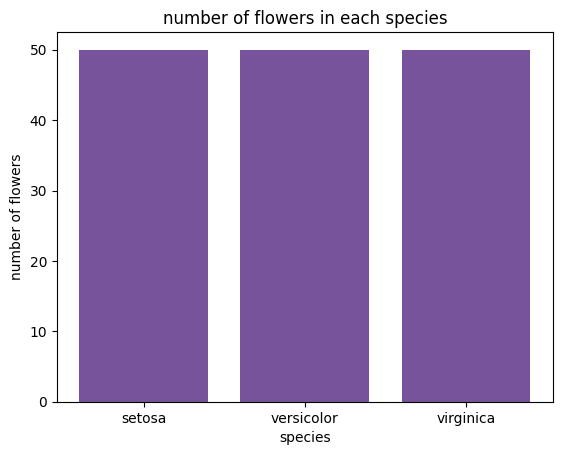

In [7]:
count= df["species"].value_counts().sort_index()

plt.bar(count.index, count.values, color="#76539B")
plt.xlabel("species")
plt.ylabel("number of flowers")
plt.xticks(count.index, iris.target_names)
plt.title("number of flowers in each species")
plt.show()

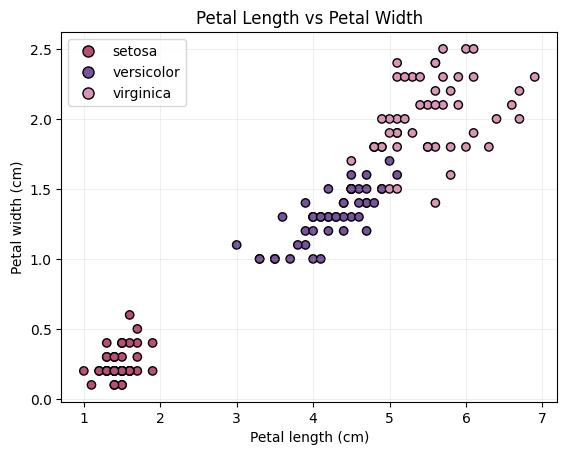

In [8]:
petalLength = df["petal length (cm)"]
petalWidth = df["petal width (cm)"]

my_colors = ["#B94E77", "#76539B", "#D995B5"]
my_cmap = ListedColormap(my_colors)

setosa = Line2D([0], [0], marker="o", color="w", markerfacecolor=my_colors[0], markeredgecolor="black", markersize=8, label="setosa")
versicolor = Line2D([0], [0],  marker="o", color="w", markerfacecolor=my_colors[1], markeredgecolor="black", markersize=8, label="versicolor")
virginica = Line2D([0], [0],  marker="o", color="w", markerfacecolor=my_colors[2], markeredgecolor="black", markersize=8, label="virginica")

plt.scatter(x=petalLength,y=petalWidth, c= df["species"], cmap=my_cmap, edgecolors="black")
plt.legend(handles=[setosa, versicolor, virginica], loc="best")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal Length vs Petal Width")
plt.grid(True, alpha=0.2)
plt.show()

In [9]:
feature = df.drop(columns=["species"])
correlation_matrix = feature.corr()

display(correlation_matrix)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


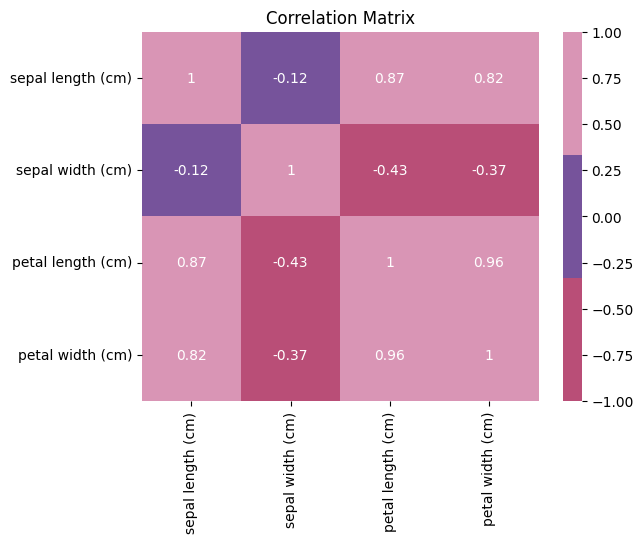

In [10]:
sns.heatmap(correlation_matrix, annot=True, cmap=my_cmap, vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

In [11]:
X = df.drop(columns=["species"])
y = df["species"]
print(X.shape)
print(y.shape)

(150, 4)
(150,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(120, 4)
(30, 4)
(120,)
(30,)


In [13]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [14]:
y_pred = knn.predict(X_test)
print(y_pred[:5])

[0 2 1 1 0]


In [15]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 1.0


In [16]:
train_pred = knn.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)
print(f"Train Accuracy: {train_accuracy}")

Train Accuracy: 0.9583333333333334


Text(0.5, 1.0, 'KNN Confusion Matrix')

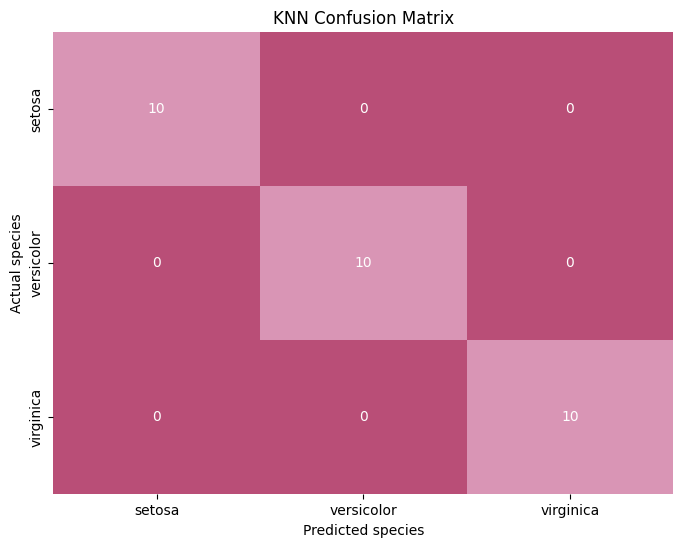

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap=my_cmap, xticklabels=iris.target_names,yticklabels=iris.target_names, cbar=False)
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("KNN Confusion Matrix")

In [18]:
precision = precision_score(y_test, y_pred, average="macro")
print("Precision:",  precision)

Precision: 1.0


In [19]:
recall = recall_score(y_test, y_pred, average="macro")
print("Recall:", recall)

Recall: 1.0


In [20]:
f1 = f1_score(y_test, y_pred, average="macro")
print("F1 Score:", f1)

F1 Score: 1.0


In [21]:
report = classification_report(y_test, y_pred, target_names=iris.target_names)
print("Classification Report:\n", report)

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [22]:
cv = cross_val_score(knn, X, y, cv=5, scoring="accuracy")
print("Cross-validation scores:", cv)
print("Mean accuracy:", cv.mean())
print("Standard deviation:", cv.std())

Cross-validation scores: [0.96666667 0.96666667 0.93333333 0.96666667 1.        ]
Mean accuracy: 0.9666666666666668
Standard deviation: 0.02108185106778919


In [23]:
k_values = list(range(1, 16,2))
print(k_values)

[1, 3, 5, 7, 9, 11, 13, 15]


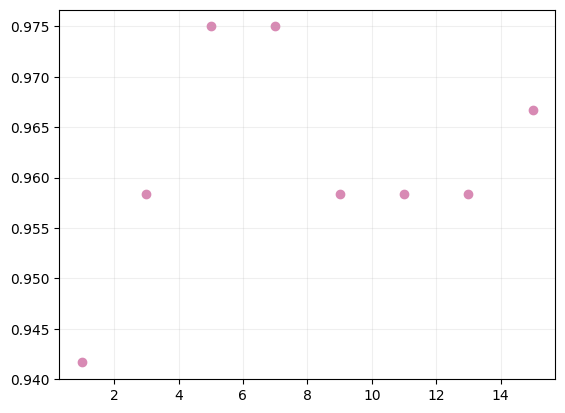

In [24]:
mean_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")

    mean_scores.append(scores.mean())
plt.scatter(k_values, mean_scores, marker="o" , color="#D88AB4")
plt.grid(True, alpha= 0.2)

In [25]:
best_k = k_values[mean_scores.index(max(mean_scores))]
print("Best k value:", best_k)

Best k value: 5


In [26]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)

KNeighborsClassifier()

In [28]:
best_y_pred = best_knn.predict(X_test)
best_y_accuracy = accuracy_score(y_test, best_y_pred)
print("original KNN Accuracy:", accuracy)
print("Best KNN Accuracy:", best_y_accuracy)

original KNN Accuracy: 1.0
Best KNN Accuracy: 1.0


In [30]:
new_flower = pd.DataFrame([[6.0,2.9,4.3,1.3]],columns=iris.feature_names)


predication = best_knn.predict(new_flower)
species_name = iris.target_names[predication[0]]
print("Predicted Species:",  species_name)

Predicted Species: versicolor


In [32]:
joblib.dump(best_knn, "iris_knn_model.joblib")

['iris_knn_model.joblib']

In [33]:
loaded_model = joblib.load("iris_knn_model.joblib")

In [35]:
predication = loaded_model.predict(new_flower)